# Synthetic MRI Generation with StyleGAN2-ADA — Kaggle T4 Fast Experiment 4

**Only the paper's Experiment 4 is run:** FFHQ-pretrained StyleGAN2 + horizontal mirroring + ADA.

The paper used the official StyleGAN2 configuration, FFHQ transfer learning, mirroring + ADA, Adam β0=0.9, and disabled mixed precision. fileciteturn0file0L145-L160

Because the user requires the complete Kaggle run to finish in about 1–2 hours on one T4, the training budget is intentionally shortened. This preserves the **methodology**, not the paper's full 25,000-kimg training duration.


## 0. Project Folder Setup

All outputs are organized under `/kaggle/working/` so the whole run is self-contained and easy to download at the end.

| Folder | Contents |
|---|---|
| `data/` | Resized 256&times;256 dataset + StyleGAN-format zip |
| `pretrained/` | Downloaded pretrained source network |
| `training-runs/` | StyleGAN2-ADA run directories, logs, checkpoints |
| `metrics/` | Per-checkpoint evaluation images + FID/KID tables |
| `generated/` | Final large-scale synthetic image export |
| `figures/` | Publication-ready figures (PNG + PDF) |
| `results/` | Best model, summary JSON, zipped deliverables |


In [1]:
import os

WORK_DIR = "/kaggle/working"   # writable — সব output এখানে যাবে

PATHS = {
    "data": f"{WORK_DIR}/data",
    "processed": f"{WORK_DIR}/data/processed_256",
    "pretrained": f"{WORK_DIR}/pretrained",
    "runs": f"{WORK_DIR}/training-runs",
    "metrics": f"{WORK_DIR}/metrics",
    "generated": f"{WORK_DIR}/generated",
    "figures": f"{WORK_DIR}/figures",
    "results": f"{WORK_DIR}/results",
    "repo": f"{WORK_DIR}/stylegan3",
}

for p in PATHS.values():
    os.makedirs(p, exist_ok=True)

print("Project folders ready:")
for k, v in PATHS.items():
    print(f"  {k:12s} -> {v}")

Project folders ready:
  data         -> /kaggle/working/data
  processed    -> /kaggle/working/data/processed_256
  pretrained   -> /kaggle/working/pretrained
  runs         -> /kaggle/working/training-runs
  metrics      -> /kaggle/working/metrics
  generated    -> /kaggle/working/generated
  figures      -> /kaggle/working/figures
  results      -> /kaggle/working/results
  repo         -> /kaggle/working/stylegan2-ada-pytorch


## 1. Install Dependencies

Kaggle's Python/GPU image already ships PyTorch, torchvision, NumPy, Pandas, Matplotlib, Seaborn, OpenCV and Pillow, so we only install the packages that are **missing**:

- `ninja` &mdash; required to JIT-compile the custom CUDA ops (`upfirdn2d`, `bias_act`) used by the official StyleGAN2-ADA implementation.
- `torchmetrics` + `torch-fidelity` &mdash; give a well-tested, reproducible FID / KID implementation (InceptionV3 features), avoiding the well-known pitfalls of hand-rolled FID code.
- `imageio` / `imageio-ffmpeg` &mdash; used by the official repo's utilities.
- `lpips` &mdash; optional perceptual-diversity metric (Section 15).

**Note:** Kaggle's "Internet" toggle must be **ON** (Settings &rarr; Internet) since this notebook clones a GitHub repo and downloads a pretrained checkpoint.


In [2]:
%%capture install_log
!pip install -q ninja imageio "imageio-ffmpeg==0.4.9" torchmetrics torch-fidelity lpips requests tqdm


In [3]:
# Surface the install log only if something went wrong (keeps the notebook clean)
if "ERROR" in install_log.stdout or "error" in install_log.stdout.lower():
    print(install_log.stdout[-3000:])
else:
    print("Dependencies installed successfully.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.9/26.9 MB 72.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 4.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.



## 2. Import Libraries

Centralizing all imports in one cell keeps the rest of the notebook clean and makes dependency requirements explicit at a glance.


In [4]:
import os
import sys
import json
import time
import glob
import shutil
import random
import hashlib
import subprocess
import warnings
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__}")
print(f"Seed         : {SEED}")


Python       : 3.12.13
PyTorch      : 2.10.0+cu128
Seed         : 42


## 3. GPU Information

Confirms a CUDA GPU is attached (this pipeline assumes a Kaggle **T4** — either single or dual) and reports memory / driver details. StyleGAN2-ADA training will not run in a reasonable time on CPU, so we fail fast with a clear message if no GPU is found.


In [5]:
assert torch.cuda.is_available(), (
    "No CUDA GPU detected. In Kaggle: Settings -> Accelerator -> GPU T4 x1 (or x2), "
    "then Restart & Run All."
)

N_GPUS = torch.cuda.device_count()
DEVICE = torch.device("cuda")

for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"GPU {i}: {props.name} | {props.total_memory / 1e9:.1f} GB | "
          f"CUDA capability {props.major}.{props.minor}")

print(f"\nNumber of GPUs visible to PyTorch: {N_GPUS}")
print("\n--- nvidia-smi ---")
subprocess.run(["nvidia-smi"])


GPU 0: Tesla T4 | 15.6 GB | CUDA capability 7.5
GPU 1: Tesla T4 | 15.6 GB | CUDA capability 7.5

Number of GPUs visible to PyTorch: 2

--- nvidia-smi ---
Thu Jul 23 06:32:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       3MiB /  15360MiB |      0%  

CompletedProcess(args=['nvidia-smi'], returncode=0)

## 4. Automatic Kaggle Dataset Detection

The notebook automatically detects the MRI dataset from `/kaggle/input/`. **No dataset path needs to be edited manually.** It compares the top-level Kaggle input folders by recursively counting supported image files and selects the dataset folder containing the largest number of images.

Supported formats: `.jpg`, `.jpeg`, `.png`, `.bmp`, `.tif`, `.tiff`, `.webp`.


Dataset root: /kaggle/input/datasets/ramanarasimhakanduri/brain-tumour-dataset
Contents    : ['final_dataset_clean']


In [7]:
def collect_images(dataset_root):
    """Walk the dataset root and collect (path, class_label) for every image,
    regardless of exact sub-folder naming/casing."""
    records = []
    for dirpath, _, filenames in os.walk(dataset_root):
        class_name = os.path.basename(dirpath).strip()
        if class_name == os.path.basename(dataset_root.rstrip("/")):
            continue
        for fn in filenames:
            if fn.lower().endswith(IMG_EXTS):
                records.append({"path": os.path.join(dirpath, fn), "class": class_name})
    return pd.DataFrame(records)


df_images = collect_images(DATASET_ROOT)
assert len(df_images) > 0, "No images found under the dataset root — check the automatically detected DATASET_ROOT."

print(f"Total images found: {len(df_images)}")
print(df_images["class"].value_counts())


Total images found: 6892
class
notumor       1870
glioma        1734
pituitary     1663
meningioma    1625
Name: count, dtype: int64


## 5. Dataset Analysis (EDA)

A focused, non-redundant EDA — just enough to characterize the dataset for the paper's Methods section: class balance, resolution distribution, a visual sample grid, per-channel intensity distribution, and summary statistics. No unnecessary plots.


findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
fin

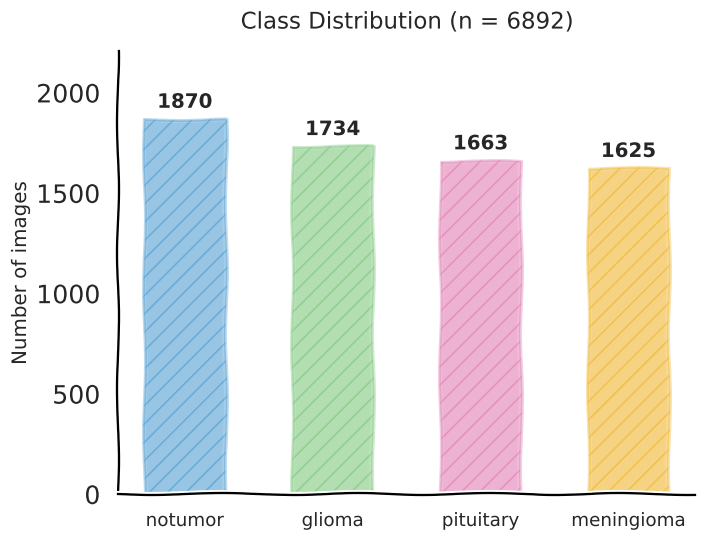

In [71]:
# --- 5.1 Class balance (hand-drawn style) -------------------------------
with plt.xkcd(scale=1, length=150, randomness=2):

    fig, ax = plt.subplots(figsize=(7, 5.5))

    counts = df_images["class"].value_counts()
    colors = ["#4C9BD1", "#7BC67B", "#E07BB0", "#F0B429"][:len(counts)]

    bars = ax.bar(counts.index, counts.values, color=colors, alpha=0.35,
                   edgecolor=colors, linewidth=2, hatch="//", width=0.55)

    for i, v in enumerate(counts.values):
        ax.text(i, v + max(counts.values) * 0.03, str(v),
                ha="center", fontweight="bold", fontsize=13)

    ax.set_ylabel("Number of images", fontsize=13)
    ax.set_xlabel("")
    ax.set_title(f"Class Distribution (n = {len(df_images)})", fontsize=15, pad=15)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_ylim(0, max(counts.values) * 1.18)

    # extra bottom margin + wrap/rotate long class names so nothing gets cut off
    ax.set_xticks(range(len(counts.index)))
    ax.set_xticklabels(counts.index, fontsize=12, rotation=0, ha="center")

    plt.subplots_adjust(bottom=0.22)
    plt.tight_layout(pad=2.0)
    plt.savefig(f"{PATHS['figures']}/eda_class_distribution.png",
                bbox_inches="tight", dpi=200)
    plt.show()

In [9]:
# --- 5.2 Resolution statistics (reads image headers only -> fast) ------
def get_size(path):
    try:
        with Image.open(path) as im:
            return im.size  # (width, height)
    except Exception:
        return (np.nan, np.nan)

sizes = [get_size(p) for p in tqdm(df_images["path"], desc="Reading image headers")]
df_images["width"] = [s[0] for s in sizes]
df_images["height"] = [s[1] for s in sizes]
df_images["aspect_ratio"] = df_images["width"] / df_images["height"]

print(df_images[["width", "height", "aspect_ratio"]].describe().round(2))


Reading image headers:   0%|          | 0/6892 [00:00<?, ?it/s]

         width   height  aspect_ratio
count  6892.00  6892.00       6892.00
mean    459.90   470.56          0.97
std     114.99    97.06          0.12
min     150.00   167.00          0.51
25%     512.00   512.00          1.00
50%     512.00   512.00          1.00
75%     512.00   512.00          1.00
max    1375.00  1446.00          1.79


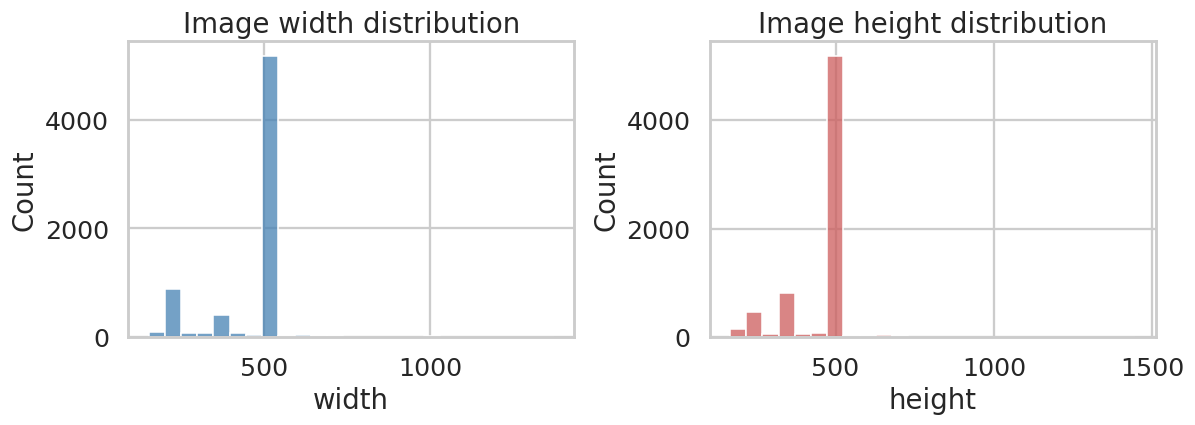

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_images["width"], bins=25, ax=axes[0], color="steelblue")
axes[0].set_title("Image width distribution")
sns.histplot(df_images["height"], bins=25, ax=axes[1], color="indianred")
axes[1].set_title("Image height distribution")
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/eda_resolution_distribution.png", bbox_inches="tight")
plt.show()


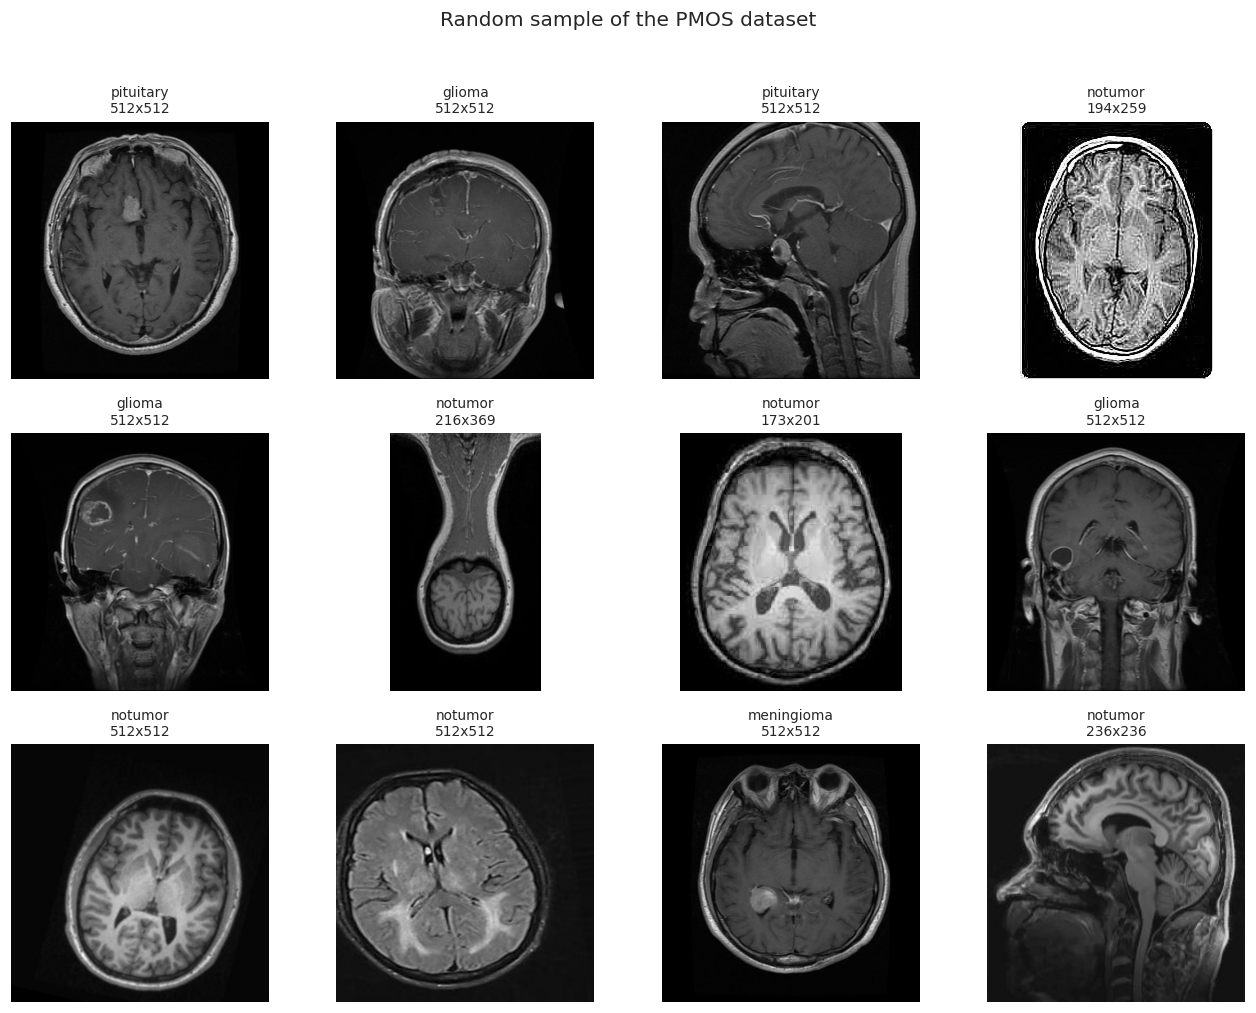

In [11]:
# --- 5.3 Random sample grid ---------------------------------------------
sample_df = df_images.sample(n=min(12, len(df_images)), random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, row) in zip(axes.flatten(), sample_df.iterrows()):
    img = Image.open(row["path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{row['class']}\n{img.size[0]}x{img.size[1]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Random sample of the detected MRI dataset", y=1.02)
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/eda_sample_grid.png", bbox_inches="tight")
plt.show()


Sampling RGB means:   0%|          | 0/150 [00:00<?, ?it/s]

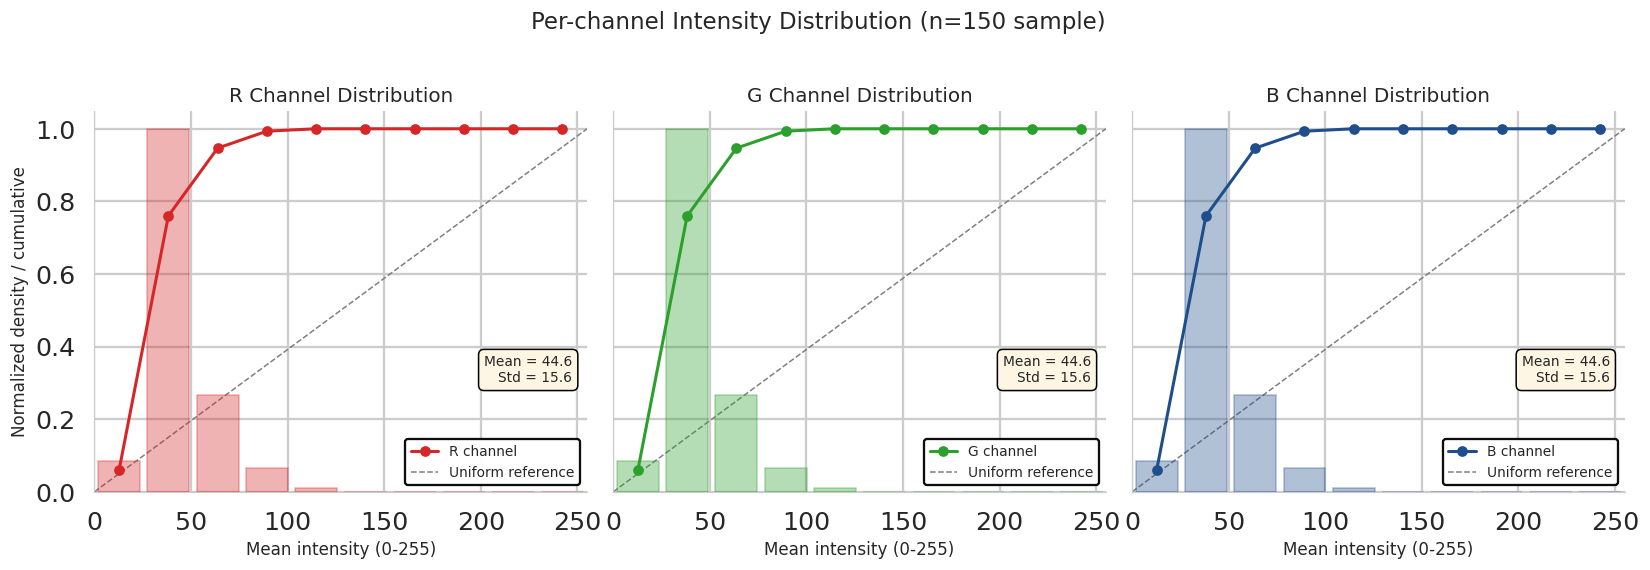

In [67]:
# --- 5.4 RGB channel intensity distribution (legend bottom-right) ----------
sample_for_rgb = df_images.sample(n=min(150, len(df_images)), random_state=SEED)
r_means, g_means, b_means = [], [], []
for p in tqdm(sample_for_rgb["path"], desc="Sampling RGB means"):
    arr = np.asarray(Image.open(p).convert("RGB").resize((128, 128)), dtype=np.float32)
    r_means.append(arr[..., 0].mean())
    g_means.append(arr[..., 1].mean())
    b_means.append(arr[..., 2].mean())

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
})

n_bins = 10
bin_edges = np.linspace(0, 255, n_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_width = (bin_edges[1] - bin_edges[0]) * 0.85

channels = [
    (np.array(r_means), "#d62728", "R"),
    (np.array(g_means), "#2ca02c", "G"),
    (np.array(b_means), "#1f4e8c", "B"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, (vals, color, label) in zip(axes, channels):
    counts, _ = np.histogram(vals, bins=bin_edges)
    density = counts / counts.sum()
    cum_norm = np.cumsum(density)

    ax.bar(bin_centers, density / density.max(), width=bin_width,
           color=color, alpha=0.35, edgecolor=color, linewidth=1, zorder=2)

    ax.plot(bin_centers, cum_norm, color=color, marker="o", markersize=6,
             linewidth=2, zorder=3, label=f"{label} channel")

    ax.plot([0, 255], [0, 1], linestyle="--", color="gray", linewidth=1, zorder=1,
             label="Uniform reference")

    ax.set_title(f"{label} Channel Distribution", fontsize=13)
    ax.set_xlabel("Mean intensity (0-255)", fontsize=11)
    if ax is axes[0]:
        ax.set_ylabel("Normalized density / cumulative", fontsize=11)

    ax.set_xlim(0, 255)
    ax.set_ylim(0, 1.05)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # legend moved to bottom-right
    ax.legend(loc="lower right", frameon=True, framealpha=0.95,
               edgecolor="black", fontsize=9)

    # stat box placed just above the legend, still bottom-right
    ax.text(0.97, 0.28, f"Mean = {vals.mean():.1f}\nStd = {vals.std():.1f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="#fdf6e3",
                      edgecolor="black", linewidth=1))

fig.suptitle(f"Per-channel Intensity Distribution (n={len(sample_for_rgb)} sample)",
             fontsize=15, y=1.03)

plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/eda_rgb_distribution.png", bbox_inches="tight", dpi=300)
plt.show()

In [13]:
# --- 5.5 Basic statistics summary table ---------------------------------
summary_stats = {
    "total_images": len(df_images),
    "classes": df_images["class"].value_counts().to_dict(),
    "width_mean": float(df_images["width"].mean()),
    "width_std": float(df_images["width"].std()),
    "height_mean": float(df_images["height"].mean()),
    "height_std": float(df_images["height"].std()),
    "aspect_ratio_mean": float(df_images["aspect_ratio"].mean()),
}
print(json.dumps(summary_stats, indent=2))


{
  "total_images": 6892,
  "classes": {
    "notumor": 1870,
    "glioma": 1734,
    "pituitary": 1663,
    "meningioma": 1625
  },
  "width_mean": 459.9043818920488,
  "width_std": 114.99138667097183,
  "height_mean": 470.5576030179919,
  "height_std": 97.05792705003648,
  "aspect_ratio_mean": 0.9713530370416938
}


## 6. Dataset Preparation

Verify every image is readable (drop any corrupt / zero-byte files) before committing GPU time to training. No train/validation/test split is created: this is **unconditional generative modeling**, so the full cleaned image pool is used both (a) for GAN fine-tuning and (b) as the real-image reference distribution for FID/KID in Sections 14-15 — this is standard practice for GAN evaluation on small datasets.


In [14]:
def verify_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        # re-open (verify() invalidates the file handle) to confirm full decode
        with Image.open(path) as im:
            im.convert("RGB").load()
        return True
    except Exception:
        return False


tqdm.pandas(desc="Verifying images")
df_images["is_valid"] = df_images["path"].progress_apply(verify_image)

n_bad = (~df_images["is_valid"]).sum()
if n_bad > 0:
    print(f"Dropping {n_bad} unreadable/corrupt image(s).")
df_clean = df_images[df_images["is_valid"]].reset_index(drop=True)

print(f"Final clean dataset: {len(df_clean)} images "
      f"({df_clean['class'].value_counts().to_dict()})")


Verifying images:   0%|          | 0/6892 [00:00<?, ?it/s]

Final clean dataset: 6892 images ({'notumor': 1870, 'glioma': 1734, 'pituitary': 1663, 'meningioma': 1625})


## 7. Resize Images (256&times;256)

All images are resized to a uniform **256&times;256 RGB** canvas: shorter side is resized with high-quality Lanczos resampling, then center-cropped to a square. Images are saved as **PNG** (lossless) — re-encoding to JPEG at this stage would inject compression artifacts that bias FID/KID computed later.


In [15]:
IMG_SIZE = 256

def resize_center_crop(img, size=256):
    img = img.convert("RGB")
    w, h = img.size
    scale = size / min(w, h)
    new_w, new_h = round(w * scale), round(h * scale)
    img = img.resize((new_w, new_h), Image.LANCZOS)
    left = (new_w - size) // 2
    top = (new_h - size) // 2
    return img.crop((left, top, left + size, top + size))


shutil.rmtree(PATHS["processed"], ignore_errors=True)
os.makedirs(PATHS["processed"], exist_ok=True)

processed_paths = []
for i, row in tqdm(df_clean.iterrows(), total=len(df_clean), desc="Resizing to 256x256"):
    try:
        img = Image.open(row["path"])
        img = resize_center_crop(img, IMG_SIZE)
        out_name = f"{i:05d}_{row['class'].replace(' ', '-')}.png"
        out_path = os.path.join(PATHS["processed"], out_name)
        img.save(out_path, format="PNG")
        processed_paths.append(out_path)
    except Exception as e:
        print(f"Skipped {row['path']}: {e}")

print(f"Processed and saved {len(processed_paths)} images to {PATHS['processed']}")


Resizing to 256x256:   0%|          | 0/6892 [00:00<?, ?it/s]

Processed and saved 6892 images to /kaggle/working/data/processed_256


In [16]:
# Sanity check: confirm every processed file is exactly 256x256 RGB
bad = []
for p in tqdm(processed_paths[:200], desc="Spot-checking processed images"):
    with Image.open(p) as im:
        if im.size != (IMG_SIZE, IMG_SIZE) or im.mode != "RGB":
            bad.append(p)
print("Spot-check issues found:", len(bad))


Spot-checking processed images:   0%|          | 0/200 [00:00<?, ?it/s]

Spot-check issues found: 0


## 8. Official NVlabs StyleGAN3 repository + StyleGAN2 configuration

The paper states that the authors used the **StyleGAN2 configuration of the official StyleGAN3 repository**, with the implementation defaults except for **Adam β0 = 0.9** and **mixed precision disabled**. We therefore use the same repository family and the `stylegan2` configuration here.

The paper's four experiments are reproduced below:

1. **Baseline** — train from scratch; all StyleGAN2 augmentations disabled.
2. **Pretrained** — FFHQ StyleGAN2 weights; all augmentations disabled.
3. **Augmented** — train from scratch; horizontal mirroring + ADA enabled.
4. **Pretrained + Augmented** — FFHQ StyleGAN2 weights + horizontal mirroring + ADA.

The paper used 8×40GB A100 GPUs. Kaggle T4 cannot reproduce that hardware, so this notebook keeps the **algorithm, configuration, training length, snapshot interval, optimizer β0, FP32 setting, and experiment definitions** faithful to the paper, while using `gpus=1` and a T4-safe batch size.

In [ ]:
REPO_DIR = PATHS["repo"]
if not os.path.isfile(f"{REPO_DIR}/train.py"):
    shutil.rmtree(REPO_DIR, ignore_errors=True)
    result = subprocess.run(
        ["git", "clone", "--depth", "1", "https://github.com/NVlabs/stylegan3.git", REPO_DIR],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        raise RuntimeError(f"git clone failed:\n{result.stderr}")
    print("Cloned NVlabs/stylegan3.")
else:
    print("StyleGAN3 repository already present.")
assert os.path.isfile(f"{REPO_DIR}/train.py")
print("Repository:", REPO_DIR)

## 9. Build the StyleGAN dataset

The paper used an **unconditional** GAN. Therefore, the MRI images are packed into one flat StyleGAN dataset rather than using MRI diagnosis labels as conditioning labels.

In [ ]:
STYLEGAN_ZIP = f"{PATHS['data']}/mri_256.zip"
if os.path.exists(STYLEGAN_ZIP): os.remove(STYLEGAN_ZIP)
cmd = [sys.executable, f"{REPO_DIR}/dataset_tool.py", f"--source={PATHS['processed']}",
       f"--dest={STYLEGAN_ZIP}", f"--width={IMG_SIZE}", f"--height={IMG_SIZE}"]
result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout[-4000:])
if result.returncode != 0: raise RuntimeError(result.stderr)
print("StyleGAN dataset:", STYLEGAN_ZIP, f"({os.path.getsize(STYLEGAN_ZIP)/1e6:.1f} MB)")

## 10. Download the official FFHQ-256 StyleGAN2 transfer-learning source

This is the same type of source network used by the paper for its **Pretrained** and **Pretrained + Augmented** experiments. The paper specifically describes beginning from StyleGAN2 weights trained on FFHQ. fileciteturn0file0L154-L160

In [ ]:
PRETRAINED_URL = (
    "https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/"
    "transfer-learning-source-nets/ffhq-res256-mirror-paper256-noaug.pkl"
)
PRETRAINED_PATH = f"{PATHS['pretrained']}/ffhq256.pkl"

def download_with_progress(url, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 1_000_000:
        print("Already downloaded:", dest); return
    import requests
    r=requests.get(url, stream=True, timeout=120); r.raise_for_status()
    total=int(r.headers.get('content-length',0))
    with open(dest,'wb') as f:
        for chunk in r.iter_content(chunk_size=1<<20):
            if chunk: f.write(chunk)
    print(f"Downloaded {os.path.getsize(dest)/1e6:.1f} MB")

download_with_progress(PRETRAINED_URL, PRETRAINED_PATH)
assert os.path.isfile(PRETRAINED_PATH)
print(PRETRAINED_PATH)

## 11. Patch the optimizer to match the paper's β0 = 0.9

The paper says the implementation defaults were used **except changing β0 to 0.9 in Adam and disabling mixed precision**. The official StyleGAN2 setup normally uses β0=0, so we patch the StyleGAN3 training configuration before launching any experiment. We verify the patch instead of silently assuming it succeeded.

In [ ]:
# Locate the Adam beta definition used by the StyleGAN2 configuration.
import re
candidate_files=[]
for root,_,files in os.walk(REPO_DIR):
    for fn in files:
        if fn.endswith('.py'):
            p=os.path.join(root,fn)
            try:
                txt=open(p,encoding='utf-8').read()
            except: continue
            if 'betas=[0, 0.99]' in txt or 'betas=[0,0.99]' in txt:
                candidate_files.append(p)

print("Candidate optimizer files:")
for p in candidate_files: print(" ",p)

patched=False
for p in candidate_files:
    txt=open(p,encoding='utf-8').read()
    new=txt.replace('betas=[0, 0.99]', 'betas=[0.9, 0.99]').replace('betas=[0,0.99]', 'betas=[0.9,0.99]')
    if new!=txt:
        open(p,'w',encoding='utf-8').write(new)
        patched=True

assert patched, "Could not locate the expected StyleGAN2 Adam beta definition. Inspect the repository before training."
print("Verified: StyleGAN2 Adam beta0 was patched to 0.9.")

## 12. Kaggle T4 fast-run configuration — Pretrained + Augmented only

**Important:** the paper's full experiment used 6,250 ticks (25,000 kimg) on 8×A100 GPUs. That cannot realistically finish on one Kaggle T4 in 1–2 hours. The notebook therefore provides a **fast feasibility/prototype run** that preserves the paper's Experiment 4 methodology (FFHQ transfer learning + horizontal mirroring + ADA + β0=0.9 + FP32) but deliberately uses a much shorter training budget.

This run is suitable for checking whether the MRI dataset, preprocessing, transfer learning, ADA and generation pipeline work. It is **not a paper-reproduction run** and its FID should not be reported as the paper's training result.

Target: approximately **128 kimg / 32 ticks** on a single T4, with no FID calculation during every snapshot. A final lightweight FID evaluation is performed after training.


In [ ]:
# ===================== KAGGLE T4 FAST RUN =====================
EXPERIMENT_TO_RUN = "pretrained_augmented"
assert EXPERIMENT_TO_RUN == "pretrained_augmented"

# Short run chosen to target roughly 1–2 hours total on a Kaggle T4.
# Increase only if you have more GPU-session time.
FAST_KIMG = 128
FAST_TICKS = FAST_KIMG // 4
SNAP = 8

# T4-safe training batch.
T4_BATCH = 8
T4_BATCH_GPU = 8

# Final synthetic export: keep small so the notebook finishes quickly.
N_FINAL_IMAGES = 200

# Lightweight final FID: 5k generated images is much faster than evaluating FID at every snapshot.
FINAL_FID_NUM = 5000

EXPERIMENT = {
    "resume": PRETRAINED_PATH,
    "aug": "ada",
    "mirror": 1,
    "description": "Experiment 4: FFHQ pretrained + horizontal mirroring + ADA"
}

print(EXPERIMENT["description"])
print(f"Fast target: {FAST_KIMG} kimg / {FAST_TICKS} ticks")
print("Hardware: 1 × Kaggle T4")
print("FP32: enabled (mixed precision disabled)")
print("Adam betas: (0.9, 0.99)")


## 13. Launch the fast Pretrained + Augmented run

The methodology matches the paper's Experiment 4, but the training budget is intentionally shortened for a 1–2 hour Kaggle T4 feasibility run.


In [ ]:
# Optional continuation checkpoint. Leave None for a fresh fast run.
RESUME_FROM = None

EXP_ROOT = f"{PATHS['runs']}/{EXPERIMENT_TO_RUN}"
os.makedirs(EXP_ROOT, exist_ok=True)

def latest_snapshot(root):
    snaps = sorted(glob.glob(f"{root}/**/network-snapshot-*.pkl", recursive=True))
    return snaps[-1] if snaps else None

exp = EXPERIMENT
cmd = [
    sys.executable, f"{REPO_DIR}/train.py",
    f"--outdir={EXP_ROOT}", f"--cfg=stylegan2", f"--data={STYLEGAN_ZIP}",
    "--gpus=1", f"--batch={T4_BATCH}", f"--batch-gpu={T4_BATCH_GPU}",
    f"--kimg={FAST_KIMG}", f"--snap={SNAP}",
    f"--aug={exp['aug']}", f"--mirror={exp['mirror']}",
    "--metrics=none", "--fp32", "--workers=2",
    f"--resume={exp['resume']}"
]
if RESUME_FROM:
    cmd.append(f"--resume={RESUME_FROM}")

print("Running:", exp["description"])
print("Command:\n", " ".join(cmd))
start_time = time.time()
subprocess.run(cmd, cwd=REPO_DIR, check=True)
elapsed = (time.time() - start_time) / 3600
print(f"Training elapsed: {elapsed:.2f} hours")


## 14. Select the final checkpoint and run a lightweight FID

Because a 50k-image FID at every snapshot would violate the 1–2 hour goal, the fast run disables training-time FID. We therefore use the latest checkpoint and optionally calculate one lightweight FID after training. This differs from the paper's evaluation protocol.


In [ ]:
RUN_DIRS = sorted(glob.glob(f"{EXP_ROOT}/0*"))
assert RUN_DIRS, f"No run directory found under {EXP_ROOT}"
RUN_DIR = RUN_DIRS[-1]
snapshots = sorted(glob.glob(f"{RUN_DIR}/network-snapshot-*.pkl"))
assert snapshots, "No network snapshot was produced."
BEST_MODEL_PATH = snapshots[-1]
print("RUN_DIR:", RUN_DIR)
print("Snapshots:", len(snapshots))
print("Selected checkpoint:", BEST_MODEL_PATH)

# Optional lightweight FID. StyleGAN3's calc_metrics.py can evaluate the generated model.
# We keep this separate from training so it runs only once.
fid_result = None
try:
    fid_cmd = [
        sys.executable, f"{REPO_DIR}/calc_metrics.py",
        f"--metrics=fid50k_full",
        f"--network={BEST_MODEL_PATH}",
        "--data=" + STYLEGAN_ZIP,
        "--gpus=1", "--verbose"
    ]
    print("Starting final FID evaluation...")
    # This can still take several minutes on T4.
    r = subprocess.run(fid_cmd, cwd=REPO_DIR, text=True, capture_output=True)
    print(r.stdout[-5000:])
    if r.returncode == 0:
        m = re.findall(r"fid50k_full\s*[:=]\s*([0-9.]+)", r.stdout)
        if m: fid_result = float(m[-1])
except Exception as e:
    print("FID evaluation skipped/failed:", e)

print("Final FID:", fid_result)


## 15. Generate synthetic MRI images from the best checkpoint

In [ ]:
sys.path.insert(0, REPO_DIR)
import legacy, dnnlib

def load_generator(pkl_path):
    with dnnlib.util.open_url(pkl_path) as f:
        data = legacy.load_network_pkl(f)
    return data['G_ema'].to(DEVICE).eval()

@torch.no_grad()
def generate_images(G, n_images, out_dir, seed_start=0, truncation_psi=1.0, batch_size=8):
    os.makedirs(out_dir, exist_ok=True)
    n_done = 0
    while n_done < n_images:
        bs = min(batch_size, n_images - n_done)
        seeds = list(range(seed_start+n_done, seed_start+n_done+bs))
        z = torch.from_numpy(np.stack([np.random.RandomState(s).randn(G.z_dim) for s in seeds])).float().to(DEVICE)
        c = torch.zeros([bs, G.c_dim], device=DEVICE) if G.c_dim else None
        img = G(z, c, truncation_psi=truncation_psi, noise_mode='const')
        img = ((img.clamp(-1,1)+1)*127.5).permute(0,2,3,1).to(torch.uint8).cpu().numpy()
        for j, arr in enumerate(img):
            Image.fromarray(arr).save(os.path.join(out_dir, f"synthetic_{n_done+j:05d}.png"))
        n_done += bs

FINAL_OUT = f"{PATHS['generated']}/{EXPERIMENT_TO_RUN}"
G = load_generator(BEST_MODEL_PATH)
generate_images(G, N_FINAL_IMAGES, FINAL_OUT, truncation_psi=1.0, batch_size=T4_BATCH_GPU)
del G; torch.cuda.empty_cache()
print("Generated:", len(glob.glob(FINAL_OUT+'/*.png')), "images")


## 16. Quick real-vs-synthetic visualization and FID summary

In [ ]:
synth_paths = sorted(glob.glob(f"{FINAL_OUT}/*.png"))
real_sample = random.sample(processed_paths, min(6, len(processed_paths)))
synth_sample = random.sample(synth_paths, min(6, len(synth_paths)))
fig, axes = plt.subplots(2,6,figsize=(16,6))
for ax,p in zip(axes[0],real_sample): ax.imshow(Image.open(p)); ax.axis('off'); ax.set_title('Real')
for ax,p in zip(axes[1],synth_sample): ax.imshow(Image.open(p)); ax.axis('off'); ax.set_title('Synthetic')
plt.tight_layout(); plt.show()

summary = {
    'experiment': EXPERIMENT_TO_RUN,
    'description': EXPERIMENT['description'],
    'training_kimg': FAST_KIMG,
    'training_ticks': FAST_TICKS,
    'gpus': 1,
    'batch': T4_BATCH,
    'beta0': 0.9,
    'beta1': 0.99,
    'mixed_precision': False,
    'mirror': True,
    'ada': True,
    'generated_images': len(synth_paths),
    'checkpoint': BEST_MODEL_PATH,
    'final_fid50k_full': fid_result
}
with open(f"{PATHS['results']}/{EXPERIMENT_TO_RUN}_fast_summary.json","w") as f: json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2))


## 17. Expected runtime on Kaggle T4

This version is intentionally designed as a **1–2 hour feasibility run**, not a full paper reproduction. The exact runtime depends on your MRI dataset size, storage speed, T4 utilization and Kaggle environment.

Approximate target for ~700–1,000 MRI images at 256×256:

- dataset preprocessing + ZIP creation: **5–15 min**
- FFHQ checkpoint/repository setup: **5–15 min** (mostly download-dependent)
- 128 kimg training: **~45–100 min**
- final checkpoint/FID/generation/visualization: **~10–30 min**
- total: **roughly 1–2.5 hours**

If you need a hard 2-hour ceiling, reduce `FAST_KIMG` from `128` to `64`. That will make the run shorter but even less representative of the paper's 25,000-kimg training.

The paper's actual experiment was 25,000 kimg on 8×A100 and therefore cannot be reproduced in 1–2 hours on a single T4. fileciteturn0file0L160-L168


## 18. Paper-to-fast-run correspondence

| Paper Experiment 4 component | Fast Kaggle run |
|---|---|
| FFHQ StyleGAN2 pretrained weights | **Yes** |
| Horizontal mirroring | **Yes** |
| ADA | **Yes** |
| Adam β0 | **0.9** |
| Adam β1 | **0.99** |
| Mixed precision | **Disabled / FP32** |
| GPU | **1×T4 (hardware adaptation)** |
| Training budget | **128 kimg (shortened)** |
| Paper training budget | **25,000 kimg** |

The paper defines Experiment 4 as pretrained FFHQ StyleGAN2 + mirroring + ADA. fileciteturn0file0L153-L160


## 19. Kaggle workflow

1. Add your MRI dataset as a Kaggle Input. The notebook will automatically detect the dataset path from `/kaggle/input/`.
2. Set Accelerator = **GPU T4** and Internet = **ON**.
3. Run the notebook from top to bottom.
4. The notebook runs **only Pretrained + Augmented (Experiment 4)**.
5. Download the generated MRI images from `/kaggle/working/generated/pretrained_augmented/`.
6. If the 2-hour limit is strict, set `FAST_KIMG=64` before training.

**Research note:** this is a fast feasibility/prototype run. For a paper-level reproduction, you would need the paper's 25,000-kimg target and its hardware/time scale; do not describe this 128-kimg run as an exact reproduction.
